In [1]:
from pathlib import Path
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

ENTRY_BETA_DEG = 5.0
EXIT_BETA_DEG = 3.0
MIN_SPEED_MPS = 1.0
MIN_EVENT_DURATION_S = 0.30
SMOOTHING_DURATION_S = 0.10
INITIATION_LOOKBACK_S = 0.50
RECOVERY_AUDIT_S = 1.00
EXPECTED_FILES = 22

In [2]:
possible_sources = [
    Path("VehicleDynamicsDataset/phaseclass"),
    Path("phaseclass"),
    Path("VehicleDynamicsDataset/VehicleDynamicsDataset/phaseclass"),
]

SOURCE_DIR = next(
    (
        p.resolve()
        for p in possible_sources
        if p.is_dir() and list(p.glob("*_phaseclass.csv"))
    ),
    None
)

if SOURCE_DIR is None:
    raise FileNotFoundError(
        "Could not locate phaseclass. Run this notebook from mlmini "
        "or VehicleDynamicsDataset, or update possible_sources."
    )

OUTPUT_DIR = SOURCE_DIR.parent / "phaseclass_v2"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

source_files = sorted(SOURCE_DIR.glob("*_phaseclass.csv"))

print("Source:", SOURCE_DIR)
print("Output:", OUTPUT_DIR)
print("Source CSV count:", len(source_files))

if len(source_files) != EXPECTED_FILES:
    raise ValueError(
        f"Expected {EXPECTED_FILES} source CSVs, found {len(source_files)}. "
        "Check the source directory before continuing."
    )

for file in source_files:
    shutil.copy2(file, OUTPUT_DIR / file.name)

print("Copied files:", len(source_files))

Source: /home/nikita/Documents/mlmini/VehicleDynamicsDataset/phaseclass
Output: /home/nikita/Documents/mlmini/VehicleDynamicsDataset/phaseclass_v2
Source CSV count: 22
Copied files: 22


In [3]:
files = sorted(OUTPUT_DIR.glob("*_phaseclass.csv"))

OLD_LABEL_NAMES = {
    "phase_label",
    "phase_lavel",
    "phase",
    "drift_phase",
}

OLD_DERIVED_NAMES = {
    "beta_rad",
    "beta_deg",
    "speed_mps",
    "abs_beta_deg",
    "beta_smooth_deg",
    "beta_rate_degps",
    "recovery_candidate",
    "event_id",
}

data = {}

for file in files:
    df = pd.read_csv(file)

    drop_cols = [
        col for col in df.columns
        if col.strip().lower() in OLD_LABEL_NAMES
        or col.strip().lower() in OLD_DERIVED_NAMES
    ]

    df = df.drop(columns=drop_cols, errors="ignore")
    df = df.loc[:, ~df.columns.duplicated()].copy()
    df.reset_index(drop=True, inplace=True)

    required = {"t_s", "Vx_mps", "Vy_mps"}
    missing = required - set(df.columns)

    if missing:
        raise ValueError(f"{file.name} is missing required columns: {sorted(missing)}")

    for col in ["t_s", "Vx_mps", "Vy_mps"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    data[file.name] = df

print("Loaded files:", len(data))

Loaded files: 22


In [4]:
def add_dynamics_features(df):
    df = df.copy()

    vx = df["Vx_mps"].to_numpy(dtype=float)
    vy = df["Vy_mps"].to_numpy(dtype=float)

    speed = np.hypot(vx, vy)
    beta_rad = np.arctan2(vy, vx)
    beta_deg = np.degrees(beta_rad)

    invalid = (
        ~np.isfinite(speed)
        | ~np.isfinite(beta_deg)
        | (speed < MIN_SPEED_MPS)
    )

    beta_rad[invalid] = np.nan
    beta_deg[invalid] = np.nan

    df["speed_mps"] = speed
    df["beta_rad"] = beta_rad
    df["beta_deg"] = beta_deg
    df["abs_beta_deg"] = np.abs(beta_deg)

    return df


for name in data:
    data[name] = add_dynamics_features(data[name])

display(
    pd.DataFrame([
        {
            "file": name,
            "rows": len(df),
            "valid_beta_pct": round(df["beta_deg"].notna().mean() * 100, 2),
            "max_abs_beta_deg": round(float(df["abs_beta_deg"].max()), 2),
        }
        for name, df in data.items()
    ])
)

,file,rows,valid_beta_pct,max_abs_beta_deg
0,2023-10_1_phaseclass.csv,23156,100.00,4.44
1,2023-10_2_phaseclass.csv,22866,96.32,4.86
2,2023-10_3_phaseclass.csv,23156,100.00,4.44
3,2023-10_4_phaseclass.csv,23345,89.20,8.47
4,2023-10_5_phaseclass.csv,46484,98.17,6.44
5,2023-10_6_phaseclass.csv,22115,97.02,6.72
6,2023-10_7_phaseclass.csv,26996,94.91,5.76
7,2023-10_8_phaseclass.csv,42365,98.14,5.83
8,2023-10_9_phaseclass.csv,23844,95.59,4.15
9,2023-10_phaseclass.csv,22866,96.32,4.86


In [5]:
def add_temporal_features(df):
    df = df.copy()

    t = df["t_s"].to_numpy(dtype=float)
    beta = df["abs_beta_deg"].to_numpy(dtype=float)

    valid_dt = np.diff(t)
    valid_dt = valid_dt[
        np.isfinite(valid_dt) & (valid_dt > 0)
    ]

    median_dt = np.median(valid_dt) if len(valid_dt) else 0.01

    window = max(
        1,
        int(round(SMOOTHING_DURATION_S / median_dt))
    )

    if window % 2 == 0:
        window += 1

    smooth = (
        pd.Series(beta)
        .rolling(window=window, center=True, min_periods=1)
        .median()
        .to_numpy()
    )
    smooth[~np.isfinite(beta)] = np.nan

    df["beta_smooth_deg"] = smooth
    df["beta_rate_degps"] = np.nan

    valid = (
        np.isfinite(t)
        & np.isfinite(beta)
        & np.isfinite(smooth)
    )

    step = np.diff(t, prepend=np.nan)
    breaks = (
        ~np.isfinite(step)
        | (step <= 0)
        | (step > 3 * median_dt)
        | ~valid
    )

    segment_id = np.cumsum(breaks)
    segment_id[~valid] = -1

    rate = np.full(len(df), np.nan)

    same_segment = (
        (segment_id[1:] == segment_id[:-1])
        & (segment_id[1:] >= 0)
        & valid[1:]
        & valid[:-1]
    )

    dts = np.diff(t)
    ds = np.diff(smooth)

    rate_values = np.full(len(df) - 1, np.nan)
    rate_values[same_segment] = ds[same_segment] / dts[same_segment]
    rate[1:] = rate_values

    df["beta_rate_degps"] = rate
    df["_segment_id"] = segment_id

    return df


for name in data:
    data[name] = add_temporal_features(data[name])

display(
    pd.DataFrame([
        {
            "file": name,
            "segments": int((np.unique(df["_segment_id"]) >= 0).sum()),
            "max_smooth_beta_deg": round(float(df["beta_smooth_deg"].max()), 2),
        }
        for name, df in data.items()
    ])
)

,file,segments,max_smooth_beta_deg
0,2023-10_1_phaseclass.csv,1,4.38
1,2023-10_2_phaseclass.csv,2,4.83
2,2023-10_3_phaseclass.csv,1,4.38
3,2023-10_4_phaseclass.csv,1,7.60
4,2023-10_5_phaseclass.csv,1,6.36
5,2023-10_6_phaseclass.csv,1,6.68
6,2023-10_7_phaseclass.csv,1,5.69
7,2023-10_8_phaseclass.csv,1,5.76
8,2023-10_9_phaseclass.csv,2,4.12
9,2023-10_phaseclass.csv,2,4.83


In [6]:
def detect_events(
    df,
    entry_beta=ENTRY_BETA_DEG,
    exit_beta=EXIT_BETA_DEG,
    min_duration=MIN_EVENT_DURATION_S,
):
    t = df["t_s"].to_numpy(dtype=float)
    beta = df["beta_smooth_deg"].to_numpy(dtype=float)
    segment = df["_segment_id"].to_numpy()

    events = []

    for sid in np.unique(segment):
        if sid < 0:
            continue

        idx = np.flatnonzero(segment == sid)

        if len(idx) == 0:
            continue

        valid = np.isfinite(t[idx]) & np.isfinite(beta[idx])
        idx = idx[valid]

        if len(idx) == 0:
            continue

        chunks = []
        chunk = [idx[0]]

        for j in idx[1:]:
            prev = chunk[-1]

            if j == prev + 1 and t[j] > t[prev]:
                chunk.append(j)
            else:
                chunks.append(np.asarray(chunk, dtype=int))
                chunk = [j]

        chunks.append(np.asarray(chunk, dtype=int))

        for chunk in chunks:
            active = None

            def close(a, b):
                s = int(chunk[a])
                e = int(chunk[b])
                duration = t[e] - t[s]

                if duration >= min_duration:
                    events.append({
                        "start_idx": s,
                        "end_idx": e,
                        "start_time_s": float(t[s]),
                        "end_time_s": float(t[e]),
                        "duration_s": float(duration),
                        "peak_beta_deg": float(np.nanmax(beta[s:e + 1])),
                    })

            for k, i in enumerate(chunk):
                if active is None:
                    if beta[i] >= entry_beta:
                        active = k
                elif beta[i] < exit_beta:
                    close(active, k - 1)
                    active = None

            if active is not None:
                close(active, len(chunk) - 1)

    events.sort(key=lambda e: e["start_idx"])

    return events

In [7]:
def assign_phase_labels(df, events):
    df = df.copy()

    n = len(df)
    labels = np.full(n, "NORMAL", dtype=object)
    recovery_candidate = np.zeros(n, dtype=bool)
    event_ids = np.full(n, -1, dtype=int)

    t = df["t_s"].to_numpy(dtype=float)
    beta = df["beta_smooth_deg"].to_numpy(dtype=float)
    beta_rate = df["beta_rate_degps"].to_numpy(dtype=float)

    for event_number, event in enumerate(events, start=1):
        start = event["start_idx"]
        end = event["end_idx"]

        labels[start:end + 1] = "SUSTAINED_DRIFT"
        event_ids[start:end + 1] = event_number

    for event_number, event in enumerate(events, start=1):
        lead_start_time = event["start_time_s"] - INITIATION_LOOKBACK_S

        lead_idx = np.flatnonzero(
            (t >= lead_start_time)
            & (t < event["start_time_s"])
            & np.isfinite(t)
            & np.isfinite(beta)
            & np.isfinite(beta_rate)
            & (beta >= EXIT_BETA_DEG)
            & (beta_rate >= 1.0)
        )

        lead_idx = lead_idx[labels[lead_idx] == "NORMAL"]
        labels[lead_idx] = "INITIATING_DRIFT"
        event_ids[lead_idx] = event_number

        recovery_idx = np.flatnonzero(
            (t > event["end_time_s"])
            & (t <= event["end_time_s"] + RECOVERY_AUDIT_S)
            & np.isfinite(t)
            & np.isfinite(beta)
            & np.isfinite(beta_rate)
            & (beta_rate <= 0)
        )

        recovery_idx = recovery_idx[labels[recovery_idx] == "NORMAL"]
        recovery_candidate[recovery_idx] = True

    df["event_id"] = event_ids
    df["recovery_candidate"] = recovery_candidate
    df["phase_label"] = labels

    return df


labeled_data = {}
all_events = []

for name, df in data.items():
    events = detect_events(df)

    for event in events:
        all_events.append({"file": name, **event})

    labeled_data[name] = assign_phase_labels(df, events)

print("Labeled files:", len(labeled_data))
print("Candidate events:", len(all_events))

Labeled files: 22
Candidate events: 22


In [8]:
summary_rows = []

for name, df in labeled_data.items():
    counts = df["phase_label"].value_counts()

    row = {
        "file": name,
        "rows": len(df),
        "valid_beta_rows": int(df["beta_deg"].notna().sum()),
        "drift_events": int(
            sum(e["file"] == name for e in all_events)
        ),
    }

    for cls in ["NORMAL", "INITIATING_DRIFT", "SUSTAINED_DRIFT"]:
        row[f"{cls.lower()}_count"] = int(counts.get(cls, 0))
        row[f"{cls.lower()}_pct"] = round(
            100 * counts.get(cls, 0) / max(len(df), 1), 2
        )

    row["recovery_candidates"] = int(
        df["recovery_candidate"].sum()
    )

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

print("\nOverall class distribution:")
display(
    pd.concat(
        [df["phase_label"] for df in labeled_data.values()],
        ignore_index=True
    ).value_counts().rename_axis("phase_label").to_frame("count")
)

,file,rows,valid_beta_rows,drift_events,normal_count,normal_pct,initiating_drift_count,initiating_drift_pct,sustained_drift_count,sustained_drift_pct,recovery_candidates
0,2023-10_1_phaseclass.csv,23156,23156,0,23156,100.00,0,0.00,0,0.00,0
1,2023-10_2_phaseclass.csv,22866,22024,0,22866,100.00,0,0.00,0,0.00,0
2,2023-10_3_phaseclass.csv,23156,23156,0,23156,100.00,0,0.00,0,0.00,0
3,2023-10_4_phaseclass.csv,23345,20823,2,22967,98.38,72,0.31,306,1.31,258
4,2023-10_5_phaseclass.csv,46484,45634,4,45583,98.06,300,0.65,601,1.29,481
5,2023-10_6_phaseclass.csv,22115,21456,2,21668,97.98,134,0.61,313,1.42,237
6,2023-10_7_phaseclass.csv,26996,25622,3,26445,97.96,228,0.84,323,1.20,303
7,2023-10_8_phaseclass.csv,42365,41579,4,41395,97.71,299,0.71,671,1.58,444
8,2023-10_9_phaseclass.csv,23844,22792,0,23844,100.00,0,0.00,0,0.00,0
9,2023-10_phaseclass.csv,22866,22024,0,22866,100.00,0,0.00,0,0.00,0



Overall class distribution:


,count
phase_label,
NORMAL,541144
SUSTAINED_DRIFT,3181
INITIATING_DRIFT,1450


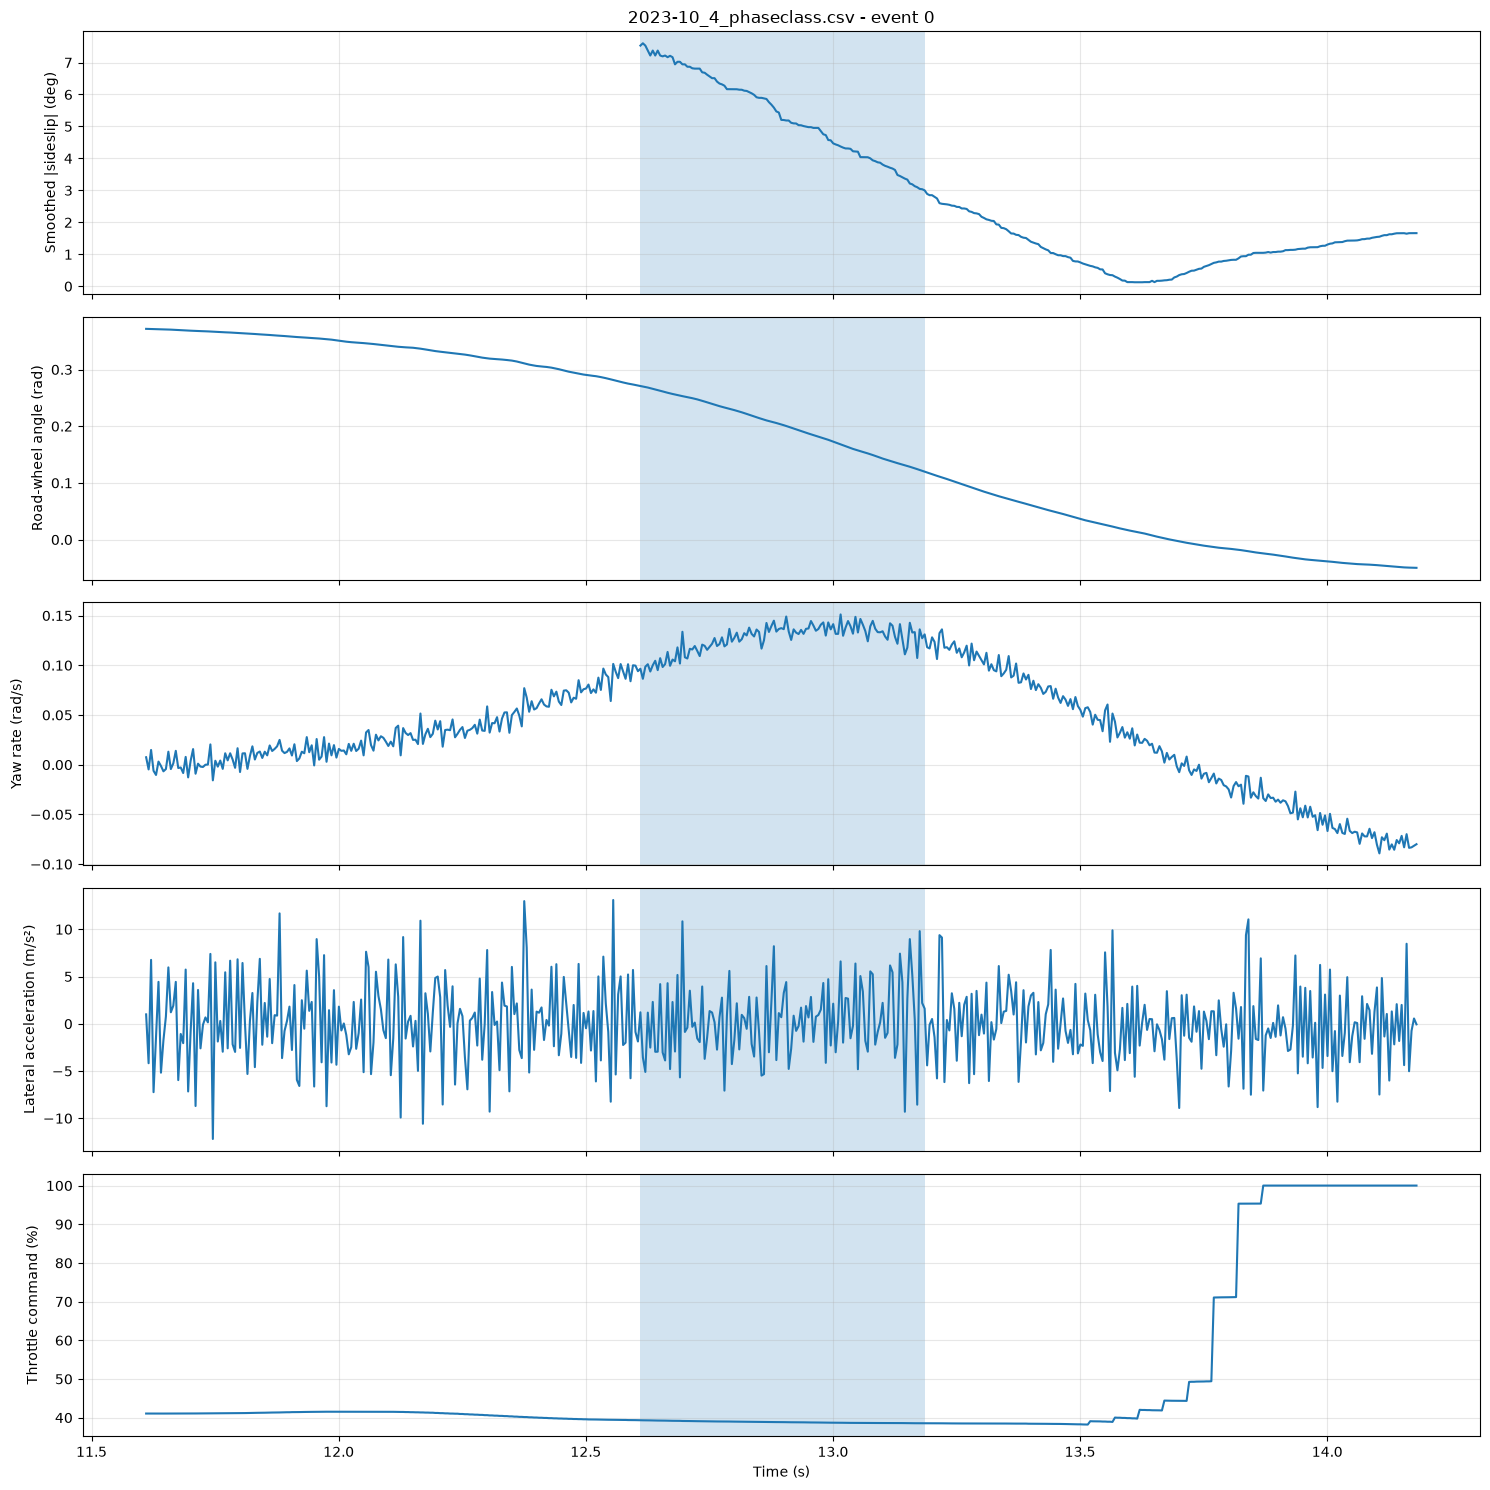

In [9]:
def plot_event(file_name, event_number=0, margin_s=1.0):
    df = labeled_data[file_name]
    events = detect_events(df)

    if not events:
        print("No candidate events in", file_name)
        return

    if event_number < 0 or event_number >= len(events):
        raise IndexError(f"Choose event_number from 0 to {len(events) - 1}")

    event = events[event_number]

    t = df["t_s"].to_numpy(dtype=float)

    lo = event["start_time_s"] - margin_s
    hi = event["end_time_s"] + margin_s

    mask = (t >= lo) & (t <= hi)

    plot_signals = [
        ("beta_smooth_deg", "Smoothed |sideslip| (deg)"),
        ("roadWheelAngle_rad", "Road-wheel angle (rad)"),
        ("yawRate_radps", "Yaw rate (rad/s)"),
        ("ayCG_mps2", "Lateral acceleration (m/s²)"),
        ("throttleCmd_percent", "Throttle command (%)"),
    ]

    available = [
        (col, title)
        for col, title in plot_signals
        if col in df.columns
    ]

    if not available:
        print("No requested plotting signals found.")
        return

    fig, axes = plt.subplots(
        len(available), 1,
        figsize=(15, 3 * len(available)),
        sharex=True
    )

    axes = np.atleast_1d(axes)

    for ax, (col, title) in zip(axes, available):
        ax.plot(t[mask], df.loc[mask, col].to_numpy(dtype=float))
        ax.axvspan(
            event["start_time_s"],
            event["end_time_s"],
            alpha=0.2
        )
        ax.set_ylabel(title)
        ax.grid(True, alpha=0.3)

    axes[0].set_title(f"{file_name} - event {event_number}")
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()


first_file_with_events = next(
    (name for name in labeled_data if any(e["file"] == name for e in all_events)),
    None
)

if first_file_with_events is not None:
    plot_event(first_file_with_events, event_number=0)

In [10]:
threshold_pairs = [
    (4.0, 2.5),
    (5.0, 3.0),
    (6.0, 4.0),
    (8.0, 5.0),
]

sensitivity_rows = []

for entry, exit_ in threshold_pairs:
    total_events = 0
    durations = []

    for name, df in data.items():
        events = detect_events(
            df,
            entry_beta=entry,
            exit_beta=exit_,
            min_duration=MIN_EVENT_DURATION_S,
        )

        total_events += len(events)
        durations.extend(e["duration_s"] for e in events)

    sensitivity_rows.append({
        "entry_beta_deg": entry,
        "exit_beta_deg": exit_,
        "total_events": total_events,
        "median_duration_s": (
            float(np.median(durations)) if durations else np.nan
        ),
        "total_drift_duration_s": float(np.sum(durations)),
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
display(sensitivity_df)

,entry_beta_deg,exit_beta_deg,total_events,median_duration_s,total_drift_duration_s
0,4.0,2.5,69,0.809929,64.550681
1,5.0,3.0,22,0.665013,15.795347
2,6.0,4.0,5,0.614990,2.770243
3,8.0,5.0,0,NaN,0.000000


In [11]:
for name, df in labeled_data.items():
    output_path = OUTPUT_DIR / name

    ordered_columns = [
        c for c in df.columns
        if c not in ("phase_label", "_segment_id")
    ] + ["phase_label"]

    df[ordered_columns].to_csv(output_path, index=False)

events_df = pd.DataFrame(all_events)
events_path = OUTPUT_DIR / "candidate_drift_events.csv"
events_df.to_csv(events_path, index=False)

summary_path = OUTPUT_DIR / "label_audit_report.csv"
summary_df.to_csv(summary_path, index=False)

sensitivity_path = OUTPUT_DIR / "threshold_sensitivity.csv"
sensitivity_df.to_csv(sensitivity_path, index=False)

print("Saved labeled CSVs to:", OUTPUT_DIR)
print("Saved event report:", events_path)
print("Saved label summary:", summary_path)
print("Saved sensitivity report:", sensitivity_path)

Saved labeled CSVs to: /home/nikita/Documents/mlmini/VehicleDynamicsDataset/phaseclass_v2
Saved event report: /home/nikita/Documents/mlmini/VehicleDynamicsDataset/phaseclass_v2/candidate_drift_events.csv
Saved label summary: /home/nikita/Documents/mlmini/VehicleDynamicsDataset/phaseclass_v2/label_audit_report.csv
Saved sensitivity report: /home/nikita/Documents/mlmini/VehicleDynamicsDataset/phaseclass_v2/threshold_sensitivity.csv


In [12]:
csv_files = sorted(OUTPUT_DIR.glob("*_phaseclass.csv"))

assert len(csv_files) == EXPECTED_FILES, (
    f"Expected {EXPECTED_FILES} labeled CSVs, found {len(csv_files)}"
)

for file in csv_files:
    df = pd.read_csv(file)

    assert "phase_label" in df.columns, f"Missing label column: {file.name}"
    assert df.columns[-1] == "phase_label", (
        f"phase_label is not the last column in {file.name}"
    )

    invalid_labels = set(df["phase_label"].dropna().unique()) - {
        "NORMAL",
        "INITIATING_DRIFT",
        "SUSTAINED_DRIFT",
    }

    assert not invalid_labels, (
        f"Unexpected labels in {file.name}: {invalid_labels}"
    )

    print(
        file.name,
        "| rows:", len(df),
        "| final column:", df.columns[-1],
        "| classes:", df["phase_label"].value_counts().to_dict()
    )

print("\nVerification complete.")

2023-10_1_phaseclass.csv | rows: 23156 | final column: phase_label | classes: {'NORMAL': 23156}
2023-10_2_phaseclass.csv | rows: 22866 | final column: phase_label | classes: {'NORMAL': 22866}
2023-10_3_phaseclass.csv | rows: 23156 | final column: phase_label | classes: {'NORMAL': 23156}
2023-10_4_phaseclass.csv | rows: 23345 | final column: phase_label | classes: {'NORMAL': 22967, 'SUSTAINED_DRIFT': 306, 'INITIATING_DRIFT': 72}
2023-10_5_phaseclass.csv | rows: 46484 | final column: phase_label | classes: {'NORMAL': 45583, 'SUSTAINED_DRIFT': 601, 'INITIATING_DRIFT': 300}
2023-10_6_phaseclass.csv | rows: 22115 | final column: phase_label | classes: {'NORMAL': 21668, 'SUSTAINED_DRIFT': 313, 'INITIATING_DRIFT': 134}
2023-10_7_phaseclass.csv | rows: 26996 | final column: phase_label | classes: {'NORMAL': 26445, 'SUSTAINED_DRIFT': 323, 'INITIATING_DRIFT': 228}
2023-10_8_phaseclass.csv | rows: 42365 | final column: phase_label | classes: {'NORMAL': 41395, 'SUSTAINED_DRIFT': 671, 'INITIATING_D